In [2]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Clean text columns
text_columns = ["Car_Name", "Fuel_Type", "Seller_Type", "Transmission"]

for column in text_columns:
    df[column] = df[column].str.strip().str.lower()

# Check dataset after cleaning
print("Dataset shape after cleaning:", df.shape)
print(df.head())

Missing values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64
Duplicate rows: 2
Dataset shape after cleaning: (299, 9)
  Car_Name  Year  Selling_Price  Present_Price  Kms_Driven Fuel_Type  \
0     ritz  2014           3.35           5.59       27000    petrol   
1      sx4  2013           4.75           9.54       43000    diesel   
2     ciaz  2017           7.25           9.85        6900    petrol   
3  wagon r  2011           2.85           4.15        5200    petrol   
4    swift  2014           4.60           6.87       42450    diesel   

  Seller_Type Transmission  Owner  
0      dealer       manual      0  
1      dealer       manual      0  
2      dealer       manual      0  
3      dealer       manual      0  
4      dealer       manual      0  


In [4]:
# Calculate car age
current_year = 2026
df["Car_Age"] = current_year - df["Year"]

# Extract brand from car name
df["Brand"] = df["Car_Name"].str.split().str[0]

# Check the new columns
print(df[["Car_Name", "Year", "Car_Age", "Brand"]].head(10))

        Car_Name  Year  Car_Age   Brand
0           ritz  2014       12    ritz
1            sx4  2013       13     sx4
2           ciaz  2017        9    ciaz
3        wagon r  2011       15   wagon
4          swift  2014       12   swift
5  vitara brezza  2018        8  vitara
6           ciaz  2015       11    ciaz
7        s cross  2015       11       s
8           ciaz  2016       10    ciaz
9           ciaz  2015       11    ciaz


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

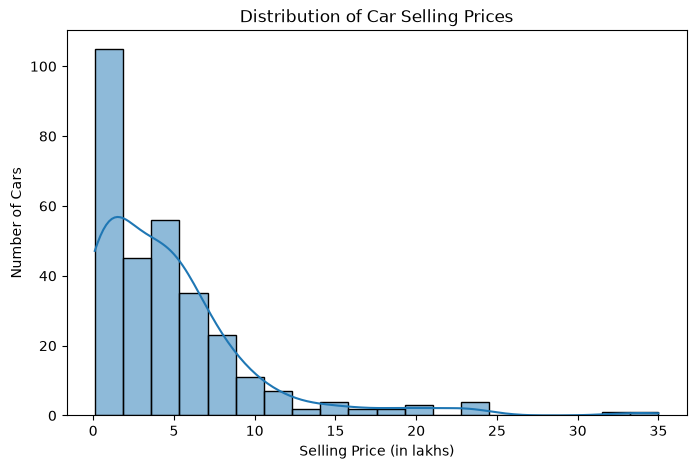

In [8]:
# Distribution of car selling prices

plt.figure(figsize=(8, 5))
sns.histplot(df["Selling_Price"], bins=20, kde=True)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price (in lakhs)")
plt.ylabel("Number of Cars")
plt.show()

In [9]:
import pandas as pd

df = pd.read_csv("car data.csv")

print(df.head())
print(df.columns)
print(df.shape)

  Car_Name  Year  Selling_Price  Present_Price  Kms_Driven Fuel_Type  \
0     ritz  2014           3.35           5.59       27000    Petrol   
1      sx4  2013           4.75           9.54       43000    Diesel   
2     ciaz  2017           7.25           9.85        6900    Petrol   
3  wagon r  2011           2.85           4.15        5200    Petrol   
4    swift  2014           4.60           6.87       42450    Diesel   

  Seller_Type Transmission  Owner  
0      Dealer       Manual      0  
1      Dealer       Manual      0  
2      Dealer       Manual      0  
3      Dealer       Manual      0  
4      Dealer       Manual      0  
Index(['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven',
       'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner'],
      dtype='str')
(301, 9)


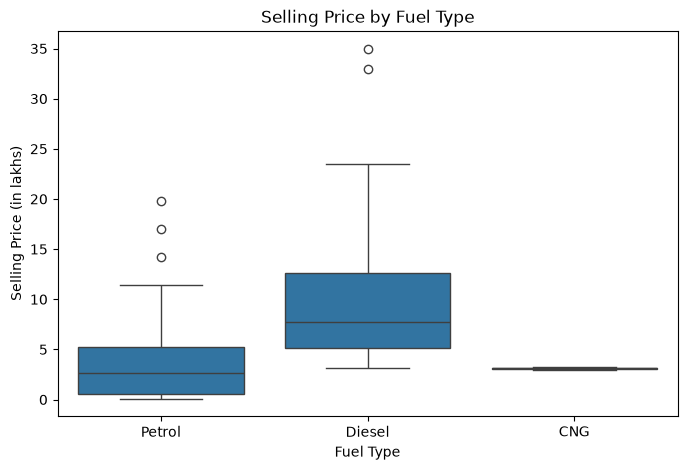

In [10]:
# Compare selling price by fuel type

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Fuel_Type", y="Selling_Price")

plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price (in lakhs)")
plt.show()

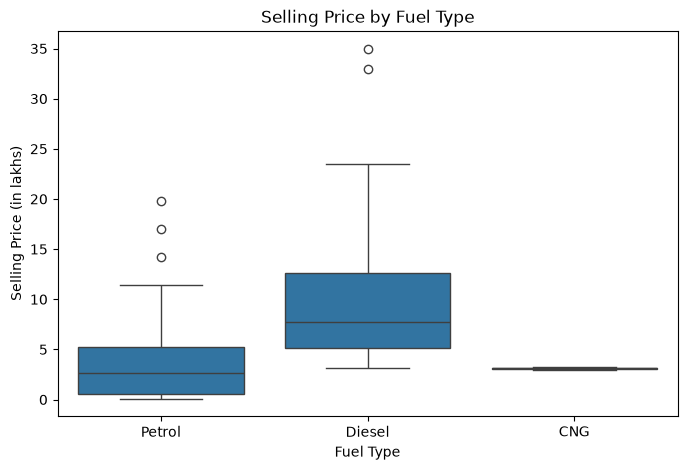

In [12]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Fuel_Type", y="Selling_Price")

plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price (in lakhs)")

plt.show()

In [14]:
print(df.columns)

Index(['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven',
       'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner'],
      dtype='str')


In [15]:
current_year = 2026

df["Car_Age"] = current_year - df["Year"]

df["Brand"] = df["Car_Name"].str.split().str[0]

print(df[["Car_Name", "Year", "Car_Age", "Brand"]].head())

  Car_Name  Year  Car_Age  Brand
0     ritz  2014       12   ritz
1      sx4  2013       13    sx4
2     ciaz  2017        9   ciaz
3  wagon r  2011       15  wagon
4    swift  2014       12  swift


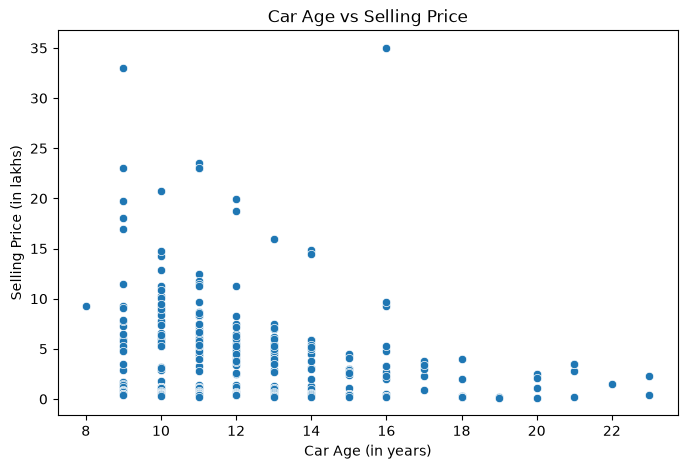

In [16]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="Car_Age", y="Selling_Price")

plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (in years)")
plt.ylabel("Selling Price (in lakhs)")

plt.show()

In [17]:
df_encoded = pd.get_dummies(
    df,
    columns=["Car_Name", "Fuel_Type", "Seller_Type", "Transmission"],
    drop_first=True,
    dtype=int
)

print("Original dataset shape:", df.shape)
print("Encoded dataset shape:", df_encoded.shape)
print(df_encoded.head())

Original dataset shape: (301, 11)
Encoded dataset shape: (301, 108)
   Year  Selling_Price  Present_Price  Kms_Driven  Owner  Car_Age  Brand  \
0  2014           3.35           5.59       27000      0       12   ritz   
1  2013           4.75           9.54       43000      0       13    sx4   
2  2017           7.25           9.85        6900      0        9   ciaz   
3  2011           2.85           4.15        5200      0       15  wagon   
4  2014           4.60           6.87       42450      0       12  swift   

   Car_Name_Activa 3g  Car_Name_Activa 4g  Car_Name_Bajaj  ct 100  ...  \
0                   0                   0                       0  ...   
1                   0                   0                       0  ...   
2                   0                   0                       0  ...   
3                   0                   0                       0  ...   
4                   0                   0                       0  ...   

   Car_Name_swift  Car_Name_sx

In [18]:
df = df.drop_duplicates().copy()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (299, 11)


In [19]:
# Input features
X = df_encoded.drop(columns=["Selling_Price", "Year", "Brand"])

# Target value
y = df_encoded["Selling_Price"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (301, 105)
Target shape: (301,)


In [21]:
# Encode the cleaned dataset
df_encoded = pd.get_dummies(
    df,
    columns=["Car_Name", "Fuel_Type", "Seller_Type", "Transmission"],
    drop_first=True,
    dtype=int
)

X = df_encoded.drop(columns=["Selling_Price", "Year", "Brand"])
y = df_encoded["Selling_Price"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (299, 105)
Target shape: (299,)


In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (239, 105)
Testing features: (60, 105)
Training target: (239,)
Testing target: (60,)


In [25]:
from sklearn.linear_model import LinearRegression

# Create the model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

# Predict car prices
lr_predictions = lr_model.predict(X_test)

print("Linear Regression model trained successfully!")
print("First 5 actual prices:", y_test.head().values)
print("First 5 predicted prices:", lr_predictions[:5])

Linear Regression model trained successfully!
First 5 actual prices: [8.99 8.35 0.45 7.45 5.25]
First 5 predicted prices: [8.73618472 8.40783981 1.14962824 6.66682169 9.70497884]


In [27]:
from sklearn.ensemble import RandomForestRegressor

# Create the model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict car prices
rf_predictions = rf_model.predict(X_test)

print("Random Forest model trained successfully!")
print("First 5 actual prices:", y_test.head().values)
print("First 5 predicted prices:", rf_predictions[:5]) 

Random Forest model trained successfully!
First 5 actual prices: [8.99 8.35 0.45 7.45 5.25]
First 5 predicted prices: [ 9.4144  7.9416  0.4408  7.2575 14.9865]


In [29]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Evaluate Linear Regression
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_r2 = r2_score(y_test, lr_predictions)

# Evaluate Random Forest
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Linear Regression Results")
print("MAE:", round(lr_mae, 2))
print("RMSE:", round(lr_rmse, 2))
print("R2 Score:", round(lr_r2, 2))

print("\nRandom Forest Results")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2 Score:", round(rf_r2, 2))

Linear Regression Results
MAE: 1.27
RMSE: 2.36
R2 Score: 0.78

Random Forest Results
MAE: 1.28
RMSE: 3.01
R2 Score: 0.65


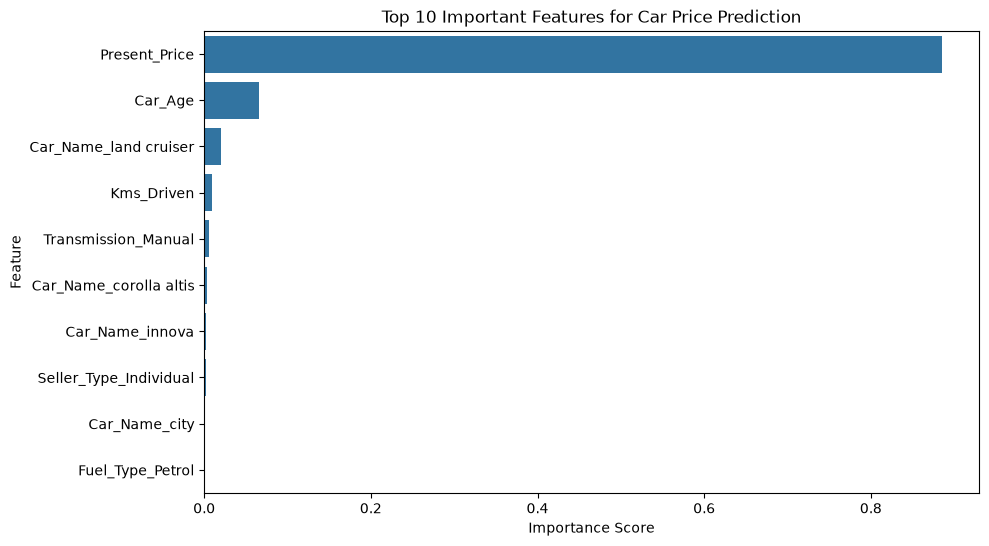

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get feature importance from Random Forest
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
importance = importance.sort_values(
    by="Importance", ascending=False
)

# Display the top 10 features
top_features = importance.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_features, x="Importance", y="Feature")

plt.title("Top 10 Important Features for Car Price Prediction")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.show()

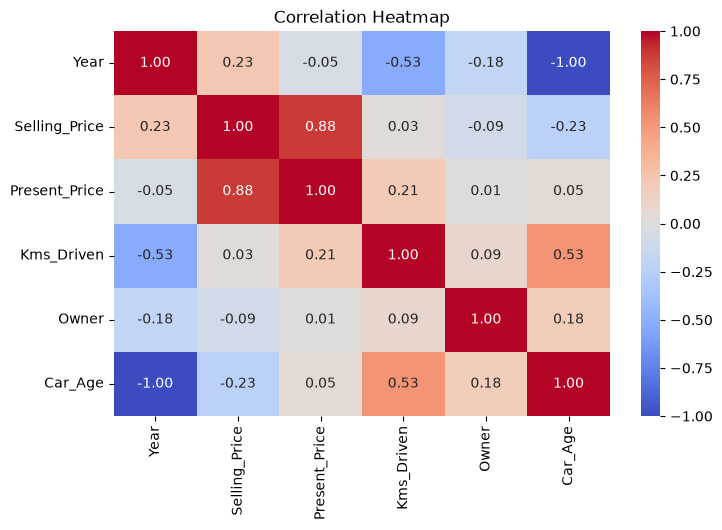

In [32]:
plt.figure(figsize=(8, 5))

numeric_df = df.select_dtypes(include="number")
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

## Conclusion

In this project, I built a machine learning model to predict used car selling prices using Python.

The dataset was cleaned by checking missing values, removing duplicate records, and preparing categorical features. Exploratory data analysis was performed using graphs to understand car prices and their relationships with different features.

Linear Regression and Random Forest Regressor models were trained and evaluated using MAE, RMSE, and R² score. Feature importance was also analysed to understand which inputs influenced the Random Forest predictions.

This project helped me understand data preprocessing, feature engineering, model training, and evaluation in a practical way.